# Q2 · Notebook 4 — BiGRU+attention vs RoBERTa: quantitative and qualitative comparison

Run after notebooks 2 and 3. `run_analysis()` reads every finished run in `outputs/`,
aggregates mean ± std over seeds and writes all tables/figures to `results/`
(`results/summary.md` collects them for the report).

In [1]:
# --- Setup: work from the project root (the folder that contains src/) ---------------
# Colab: upload q2_rating_prediction.zip, then run
#   !unzip -q q2_rating_prediction.zip -d /content && %cd /content/q2_rating_prediction
# (or keep it on Google Drive so outputs survive a disconnect - see README).
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
print("project root:", ROOT)

import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from IPython.display import Image, Markdown, display
pd.set_option("display.max_colwidth", 160)
print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

project root: /content/q2_rating_prediction


torch 2.11.0+cu130 | GPU: Tesla T4


In [2]:
from src.analysis import run_analysis
res = run_analysis(out_dir="outputs", data_dir="data", results_dir="results", explain=True)
for name, table in res["tables"].items():
    display(Markdown(f"### {name.replace('_', ' ').title()}")); display(table)

[11:24:21] runs found: BiGRU + attention: seeds [13, 42]; RoBERTa (mean pooling, len 256): seeds [13, 42]; RoBERTa (first pooling, len 256): seeds [13, 42]


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[11:24:47] wrote results/summary.md


### Main

... (3 outputs left out)

### Ordinal Errors

,Model,Exact (%),Off by 1 star (%),Off by >=2 stars (%),Errors that are adjacent (%),4<->5 confusion rate (%),1<->5 confusions (count / 5000),MAE (stars)
0,BiGRU + attention,63.72 ± 0.31,30.95 ± 0.61,5.33 ± 0.30,85.30 ± 0.94,19.38 ± 0.18,10.0 ± 0.0,0.426 ± 0.000
1,"RoBERTa (mean pooling, len 256)",66.82 ± 0.23,29.62 ± 0.31,3.56 ± 0.08,89.27 ± 0.33,18.88 ± 0.25,6.5 ± 0.7,0.373 ± 0.001
2,"RoBERTa (first pooling, len 256)",66.70 ± 0.06,29.70 ± 0.03,3.60 ± 0.08,89.19 ± 0.24,18.75 ± 0.07,5.5 ± 0.7,0.375 ± 0.002


### Ablation

,Variant,Seeds,Val macro-F1 (%),Val acc (%),Val MAE,Test macro-F1 (%),Test acc (%),Test MAE
0,"RoBERTa (mean pooling, len 256)",2,66.32 ± 0.05,66.44 ± 0.14,0.378 ± 0.002,66.70 ± 0.15,66.82 ± 0.23,0.373 ± 0.001
1,"RoBERTa (first pooling, len 256)",2,66.51 ± 0.04,66.69 ± 0.16,0.375 ± 0.003,66.50 ± 0.19,66.70 ± 0.06,0.375 ± 0.002


## Curves, confusion matrices and the ordinal error profile

* Confusion matrices are row-normalised and pooled over seeds: the diagonal is per-class
  recall. Look at how much mass sits **next to** the diagonal (adjacent ratings, e.g. 4 vs 5)
  versus **far** from it (1 vs 5).
* `error_distance.png` (log scale) shows the share of reviews predicted 0, 1, 2, 3, 4 stars
  away from the truth — MAE summarises this distribution.

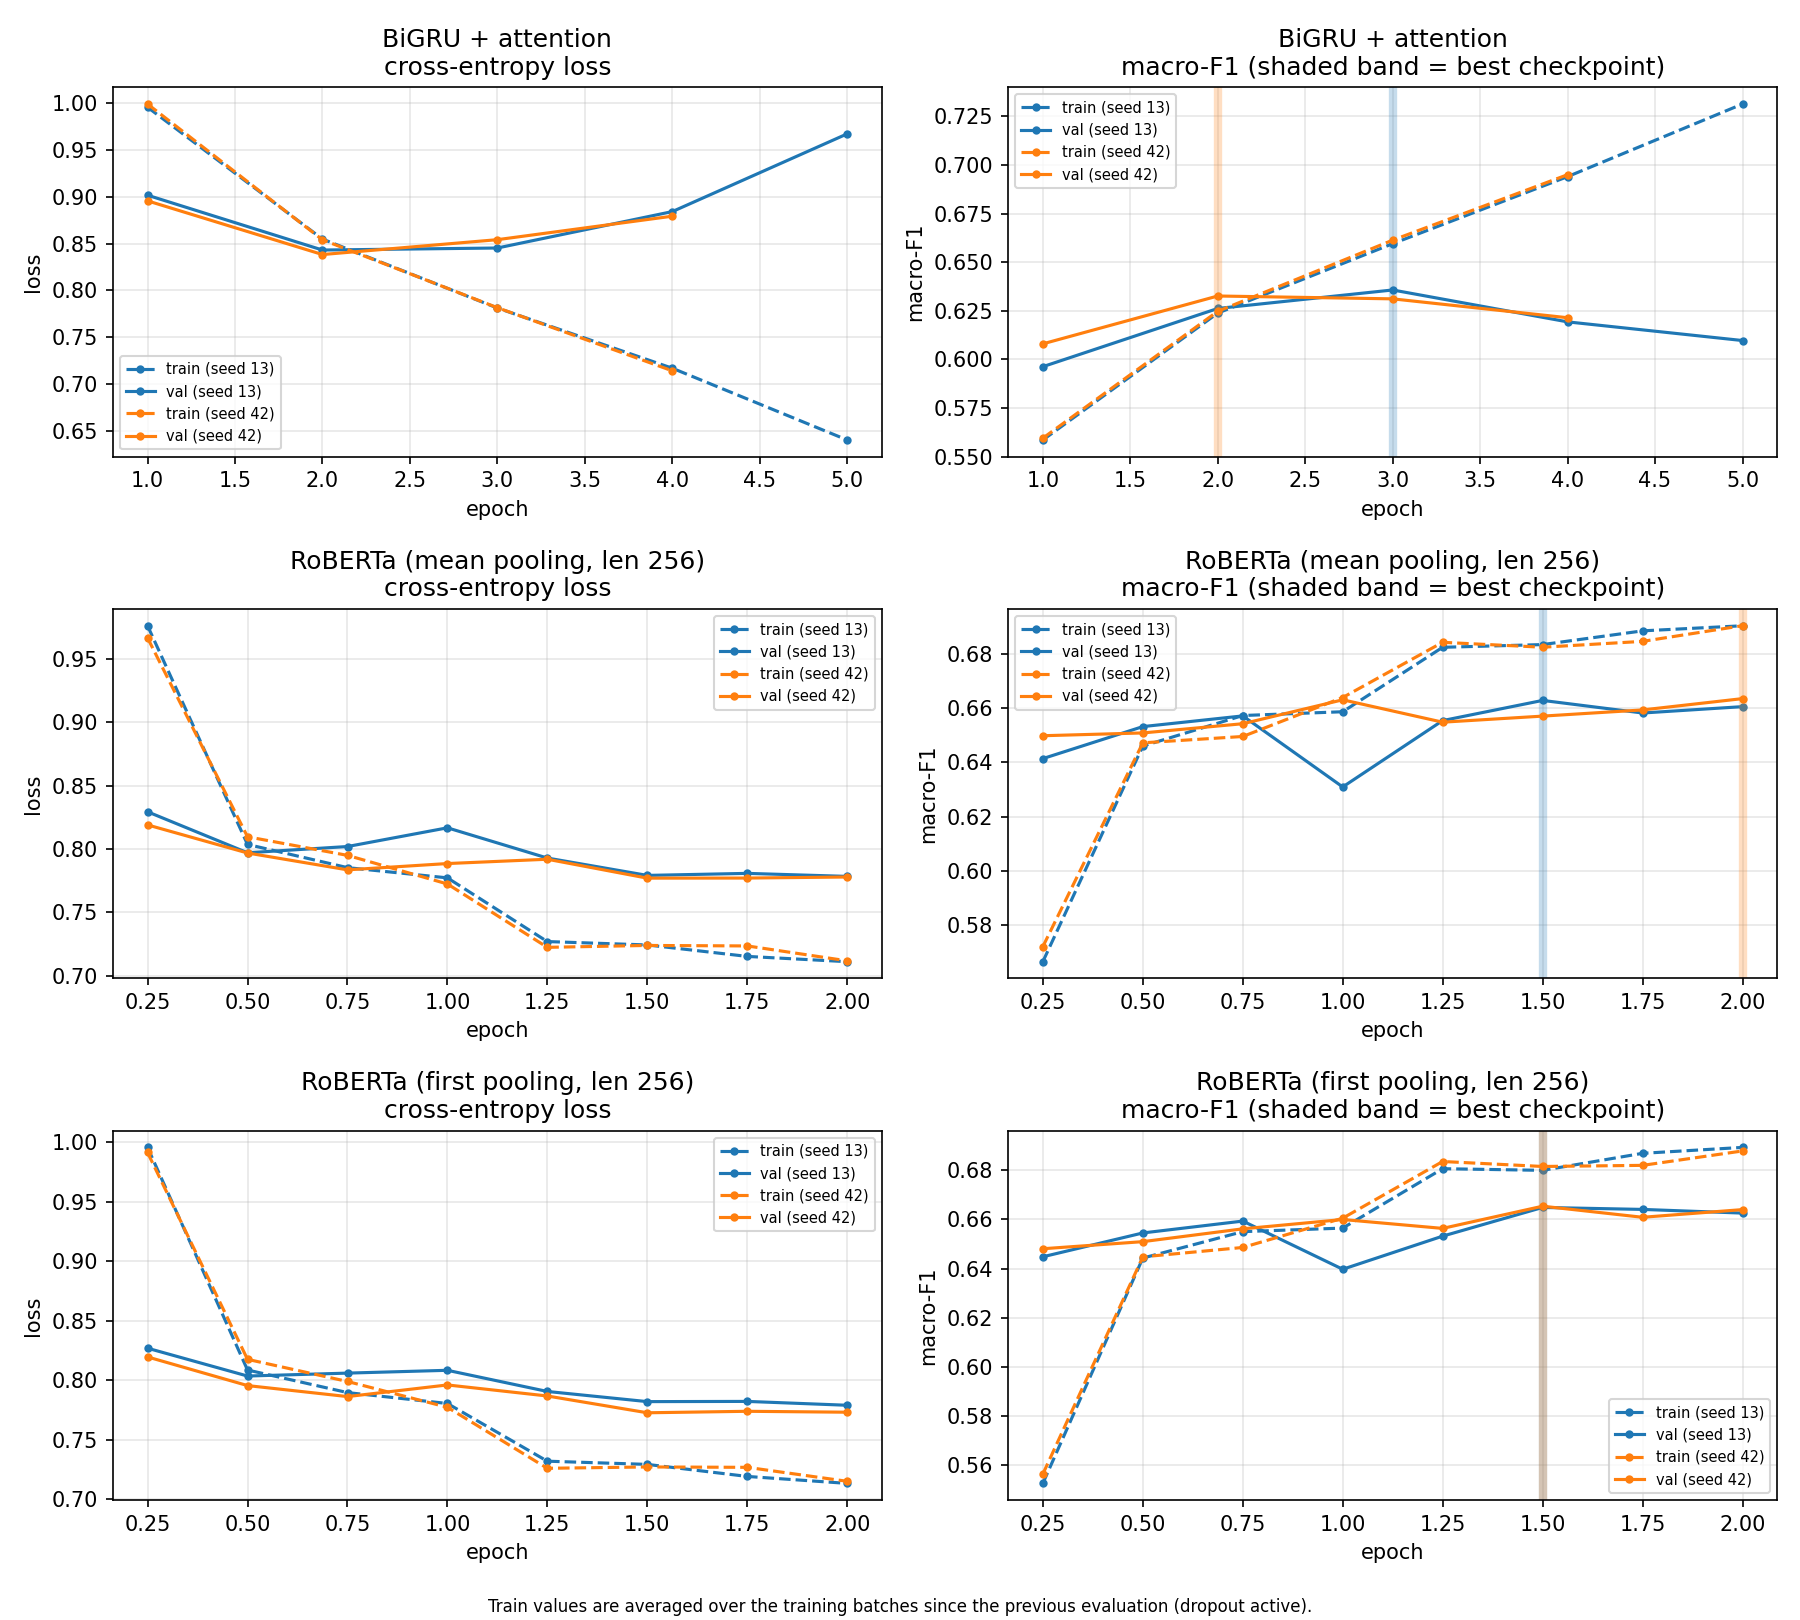

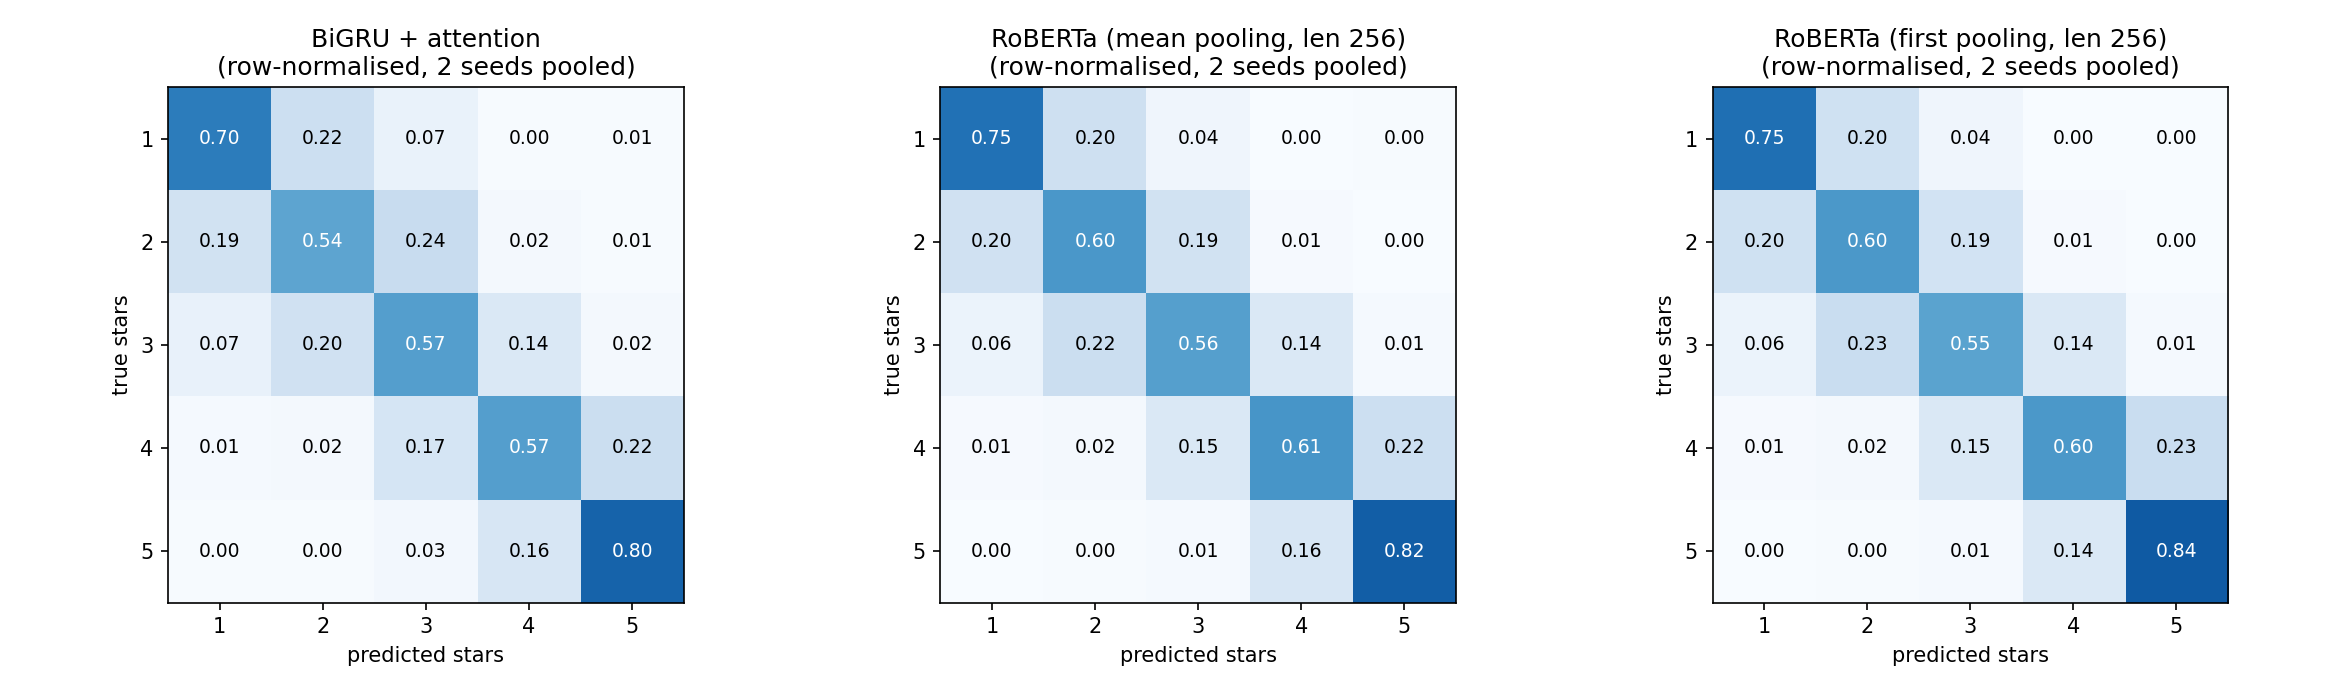

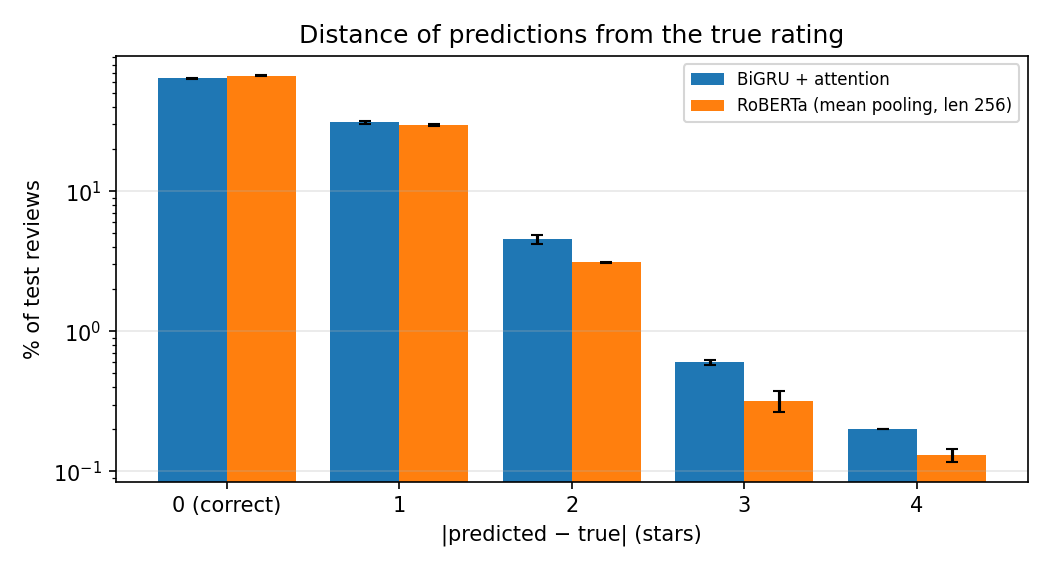

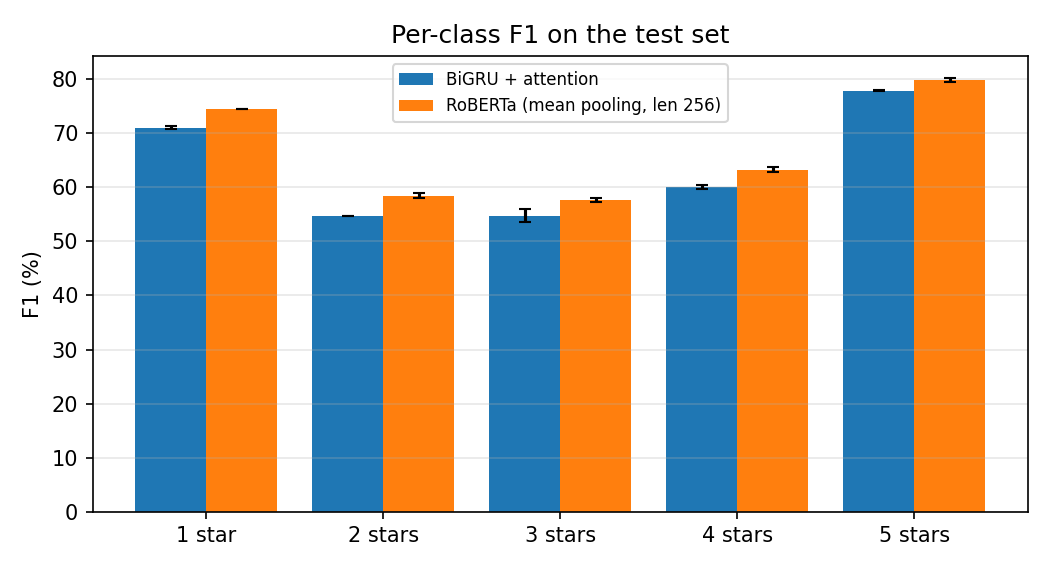

In [3]:
for f in ["curves_all.png", "confusion_matrices.png", "error_distance.png", "per_class_f1.png"]:
    display(Image(f"results/{f}"))

## Qualitative analysis

The contingency table counts test reviews by which model is right (same seed for both).
The phenomenon table shows how often each (heuristic) phenomenon appears among all test
reviews versus among the reviews only one model gets right — a phenomenon that is much more
frequent in "BiGRU wrong, RoBERTa right" than in "all test" is evidence for a hypothesis.
Tags are keyword heuristics; read each example before using it.

In [4]:
q = res["qualitative"]
display(q["contingency"])
display(q["enrichment"])

,RoBERTa correct,RoBERTa wrong
BiGRU correct,2871,326
BiGRU wrong,478,1325


,Phenomenon,% of all test,"% of BiGRU wrong, RoBERTa right","% of RoBERTa wrong, BiGRU right",% of both wrong
0,negation,52.8,62.3,54.9,55.4
1,contrast,38.8,47.3,45.7,45.4
2,mixed sentiment,13.6,17.6,14.7,15.7
3,sarcasm cue,5.8,5.0,3.7,4.2
4,polarity mismatch,7.6,13.8,4.6,11.8
5,long (>150 words),1.3,1.5,1.2,1.1
6,OOV-heavy,4.6,5.6,5.2,5.7
7,very short (<=8 words),7.2,3.3,4.9,4.4


In [5]:
display(Markdown(open("results/qualitative_baseline_fails_roberta_ok.md", encoding="utf-8").read()))

# BiGRU+attention fails, RoBERTa succeeds (test set, seed 42)

### Example 1  (id `en_0544486`)

- **True rating:** 5★
- **BiGRU+attention:** 1★ (p = 0.32)
- **RoBERTa:** 5★ (p = 0.94)
- **Phenomena (auto-tagged):** negation, sarcasm cue, polarity mismatch
- **Starting points for your hypothesis (auto-generated):**
  - *negation*: Negation reverses nearby sentiment words; the BiGRU has to carry 'not' forward to the word it modifies, while RoBERTa's self-attention lets every token see the negator directly.
  - *sarcasm cue*: Possible sarcasm / irony (heuristic flag - confirm by reading): positive surface words with a negative meaning.
  - *polarity mismatch*: The words' surface polarity disagrees with the rating (e.g. only positive words but 1-2 stars), so lexical cues mislead.

> NO PUFFING UP OR LOOSE SNAGS OF FABRIC AFTER WASH!!! I bought two sets. In White. One came with a couple light brown stains. Maybe dirt. Who knows. The lining plastic package was torn. Washed them immediately after arrival with TIDE & dirt removed! So I didn’t have to return it! The fabric does NOT puff up. Looks brand new even after wash! VERY SOFT! Wrinkle free as noted!!! Very white after washing with plain blue Tide detergent. Will buy again!!! AND AGAIN!! THANK YOU!!!

### Example 2  (id `en_0600154`)

- **True rating:** 5★
- **BiGRU+attention:** 1★ (p = 0.49)
- **RoBERTa:** 5★ (p = 0.89)
- **Phenomena (auto-tagged):** contrast, sarcasm cue, polarity mismatch
- **Starting points for your hypothesis (auto-generated):**
  - *contrast*: The review pivots ('but', 'however', ...); the star rating usually follows one side of the pivot, so the model must weigh the clauses rather than count sentiment words.
  - *sarcasm cue*: Possible sarcasm / irony (heuristic flag - confirm by reading): positive surface words with a negative meaning.
  - *polarity mismatch*: The words' surface polarity disagrees with the rating (e.g. only positive words but 1-2 stars), so lexical cues mislead.

> I don’t have cravings after taking this at night! I’m horrible with eating late at night, I do it almost every night after dinner and I’m sure it’s part of the reason I’m overweight. But when I take this, the cravings are gone!!

### Example 3  (id `en_0327365`)

- **True rating:** 5★
- **BiGRU+attention:** 1★ (p = 0.35)
- **RoBERTa:** 5★ (p = 0.36)
- **Phenomena (auto-tagged):** mixed sentiment
- **Starting points for your hypothesis (auto-generated):**
  - *mixed sentiment*: Positive and negative words co-occur; middle ratings (2-4 stars) depend on their balance.

> Grimm. I loved this show and was so disappointed when it was cancelled after six seasons.

### Example 4  (id `en_0993971`)

- **True rating:** 5★
- **BiGRU+attention:** 2★ (p = 0.32)
- **RoBERTa:** 5★ (p = 0.59)
- **Phenomena (auto-tagged):** negation, sarcasm cue
- **Starting points for your hypothesis (auto-generated):**
  - *negation*: Negation reverses nearby sentiment words; the BiGRU has to carry 'not' forward to the word it modifies, while RoBERTa's self-attention lets every token see the negator directly.
  - *sarcasm cue*: Possible sarcasm / irony (heuristic flag - confirm by reading): positive surface words with a negative meaning.

> A Very subtle and male-type Fragrance !! Would Not Use any other Cologne

### Example 5  (id `en_0544268`)

- **True rating:** 1★
- **BiGRU+attention:** 3★ (p = 0.42)
- **RoBERTa:** 1★ (p = 0.65)
- **Phenomena (auto-tagged):** polarity mismatch
- **Starting points for your hypothesis (auto-generated):**
  - *polarity mismatch*: The words' surface polarity disagrees with the rating (e.g. only positive words but 1-2 stars), so lexical cues mislead.

> My other feeders work great. Poorly made. Doest attract any birds. My other feeders work great.

### Example 6  (id `en_0494424`)

- **True rating:** 4★
- **BiGRU+attention:** 3★ (p = 0.47)
- **RoBERTa:** 4★ (p = 0.86)
- **Phenomena (auto-tagged):** negation, contrast, long (>150 words)
- **Starting points for your hypothesis (auto-generated):**
  - *negation*: Negation reverses nearby sentiment words; the BiGRU has to carry 'not' forward to the word it modifies, while RoBERTa's self-attention lets every token see the negator directly.
  - *contrast*: The review pivots ('but', 'however', ...); the star rating usually follows one side of the pivot, so the model must weigh the clauses rather than count sentiment words.
  - *long (>150 words)*: Long review: the baseline truncates at 200 tokens and squeezes everything into one attention-pooled vector; RoBERTa sees up to 256 sub-words with full self-attention.

> A great product but sloppy bushings. This thing really works to lessen the impacts. Definitely makes a hard tail bike ride much nicer. It is well made, except that there is a little more play in the bushings that I think is needed. As a result, the seat can actually rock side to side a little. This does not bother me at all when riding, and may actually be a benefit, but I worry that it will get worse as it wears. Regardless, what this seat post does is transform your hard tail bike into something you’ll will want to ride more, and it makes the bike more capable. I currently have it on a fat bike. I have another good full suspension trail bike, but I doubt that I’ll buy another FS bike, ‘cause you can get a hard tail and still have comfort if equipped with this post.

### Example 7  (id `en_0079787`)

- **True rating:** 5★
- **BiGRU+attention:** 3★ (p = 0.30)
- **RoBERTa:** 5★ (p = 0.62)
- **Phenomena (auto-tagged):** OOV-heavy
- **Starting points for your hypothesis (auto-generated):**
  - *OOV-heavy*: Several words are <unk> for the baseline (misspellings, rare words); RoBERTa's byte-level BPE never produces unknown tokens, it splits them into sub-words.

> Opinion on fangirl. This novel took my heart. If you’ve read Eleanor and Park you know your in for a whirlwind. It was everything I expected.

### Example 8  (id `en_0640800`)

- **True rating:** 4★
- **BiGRU+attention:** 3★ (p = 0.45)
- **RoBERTa:** 4★ (p = 0.59)
- **Phenomena (auto-tagged):** negation, very short (<=8 words), polarity mismatch
- **Starting points for your hypothesis (auto-generated):**
  - *negation*: Negation reverses nearby sentiment words; the BiGRU has to carry 'not' forward to the word it modifies, while RoBERTa's self-attention lets every token see the negator directly.
  - *very short (<=8 words)*: Very little evidence; a single word decides the prediction.
  - *polarity mismatch*: The words' surface polarity disagrees with the rating (e.g. only positive words but 1-2 stars), so lexical cues mislead.

> Not bad for the price


In [6]:
display(Markdown(open("results/qualitative_roberta_fails_baseline_ok.md", encoding="utf-8").read()))

# RoBERTa fails, BiGRU+attention succeeds (test set, seed 42)

### Example 1  (id `en_0540577`)

- **True rating:** 3★
- **BiGRU+attention:** 3★ (p = 0.31)
- **RoBERTa:** 1★ (p = 0.38)
- **Phenomena (auto-tagged):** negation
- **Starting points for your hypothesis (auto-generated):**
  - *negation*: Negation reverses nearby sentiment words; the BiGRU has to carry 'not' forward to the word it modifies, while RoBERTa's self-attention lets every token see the negator directly.

> Must not have bought the right style. Doesn't fit my spout must be to modern for it.

### Example 2  (id `en_0294586`)

- **True rating:** 1★
- **BiGRU+attention:** 1★ (p = 0.35)
- **RoBERTa:** 3★ (p = 0.42)
- **Phenomena (auto-tagged):** contrast, mixed sentiment
- **Starting points for your hypothesis (auto-generated):**
  - *contrast*: The review pivots ('but', 'however', ...); the star rating usually follows one side of the pivot, so the model must weigh the clauses rather than count sentiment words.
  - *mixed sentiment*: Positive and negative words co-occur; middle ratings (2-4 stars) depend on their balance.

> Broken bottle. Love the product but one was broken in box and left a awful mess.

### Example 3  (id `en_0103134`)

- **True rating:** 1★
- **BiGRU+attention:** 1★ (p = 0.30)
- **RoBERTa:** 3★ (p = 0.29)
- **Phenomena (auto-tagged):** negation, mixed sentiment
- **Starting points for your hypothesis (auto-generated):**
  - *negation*: Negation reverses nearby sentiment words; the BiGRU has to carry 'not' forward to the word it modifies, while RoBERTa's self-attention lets every token see the negator directly.
  - *mixed sentiment*: Positive and negative words co-occur; middle ratings (2-4 stars) depend on their balance.

> Product works. This review is not for the product its for the seller. There was a mistake on there part and I didn't receive the right product . Would have been too much of a hassle for me to return. Gave the tablet form vitamins to a friend. This product does work.

### Example 4  (id `en_0124671`)

- **True rating:** 4★
- **BiGRU+attention:** 4★ (p = 0.29)
- **RoBERTa:** 5★ (p = 0.87)
- **Phenomena (auto-tagged):** sarcasm cue
- **Starting points for your hypothesis (auto-generated):**
  - *sarcasm cue*: Possible sarcasm / irony (heuristic flag - confirm by reading): positive surface words with a negative meaning.

> buy it!! needs auto cut-off for alarm, loud alarm tone


## Token-importance figures for the selected example

test_en_0600154_bigru_attention.png


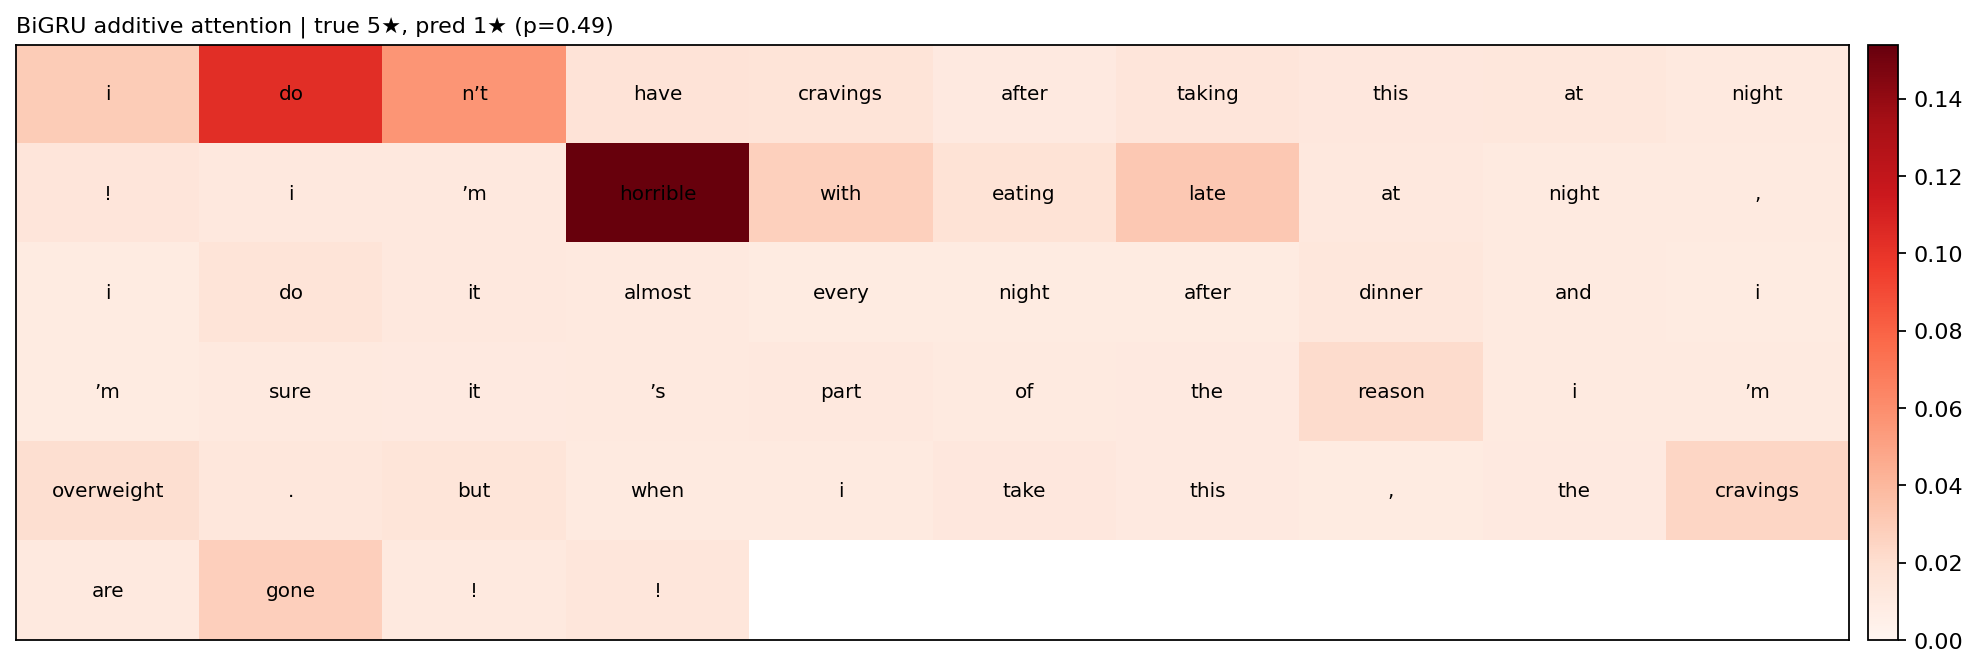

test_en_0600154_roberta_attention.png


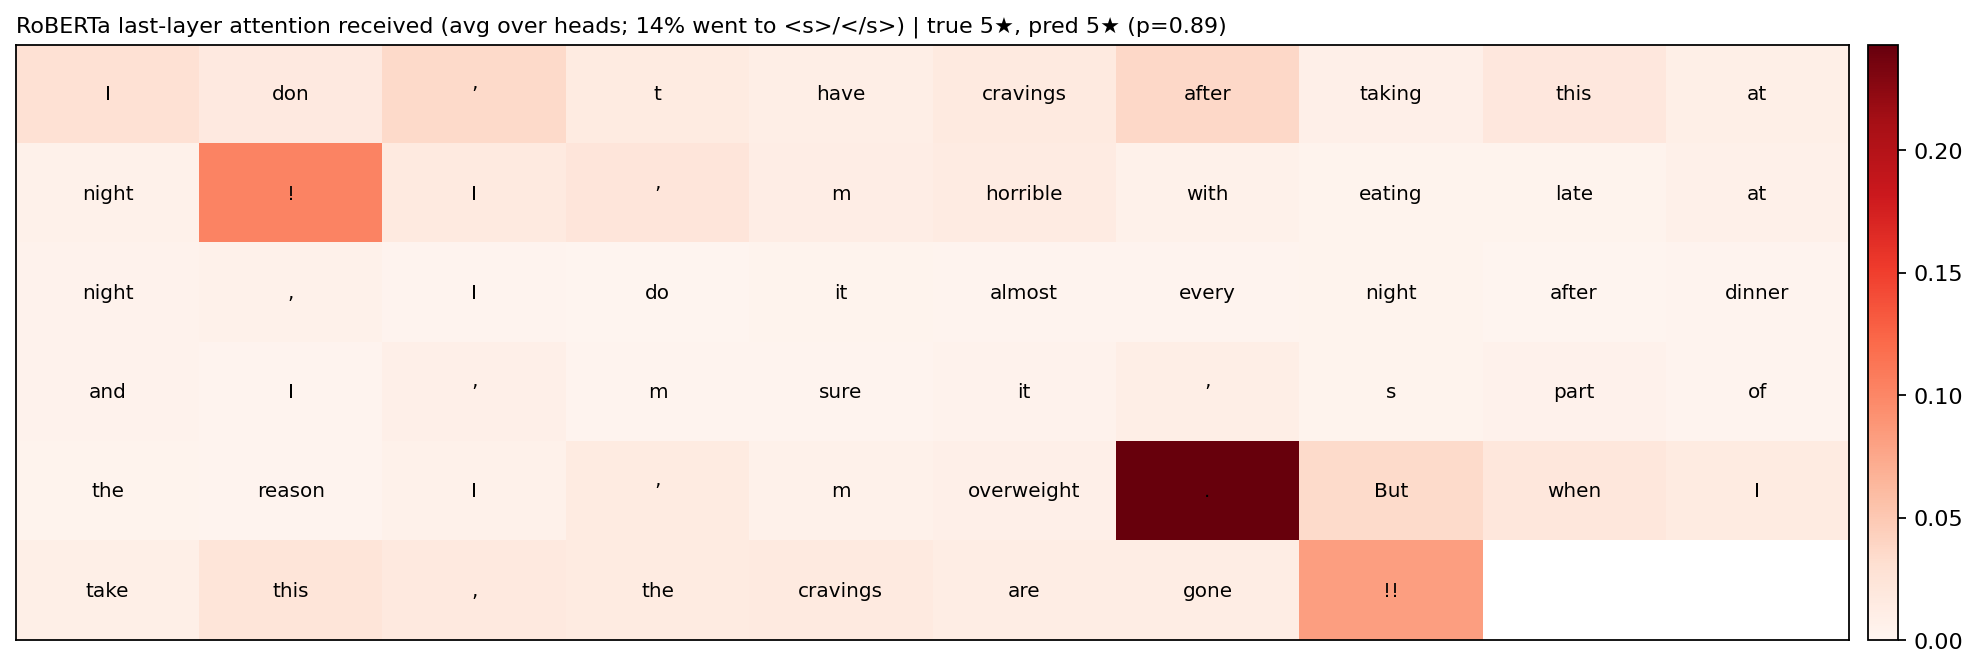

test_en_0600154_roberta_occlusion.png


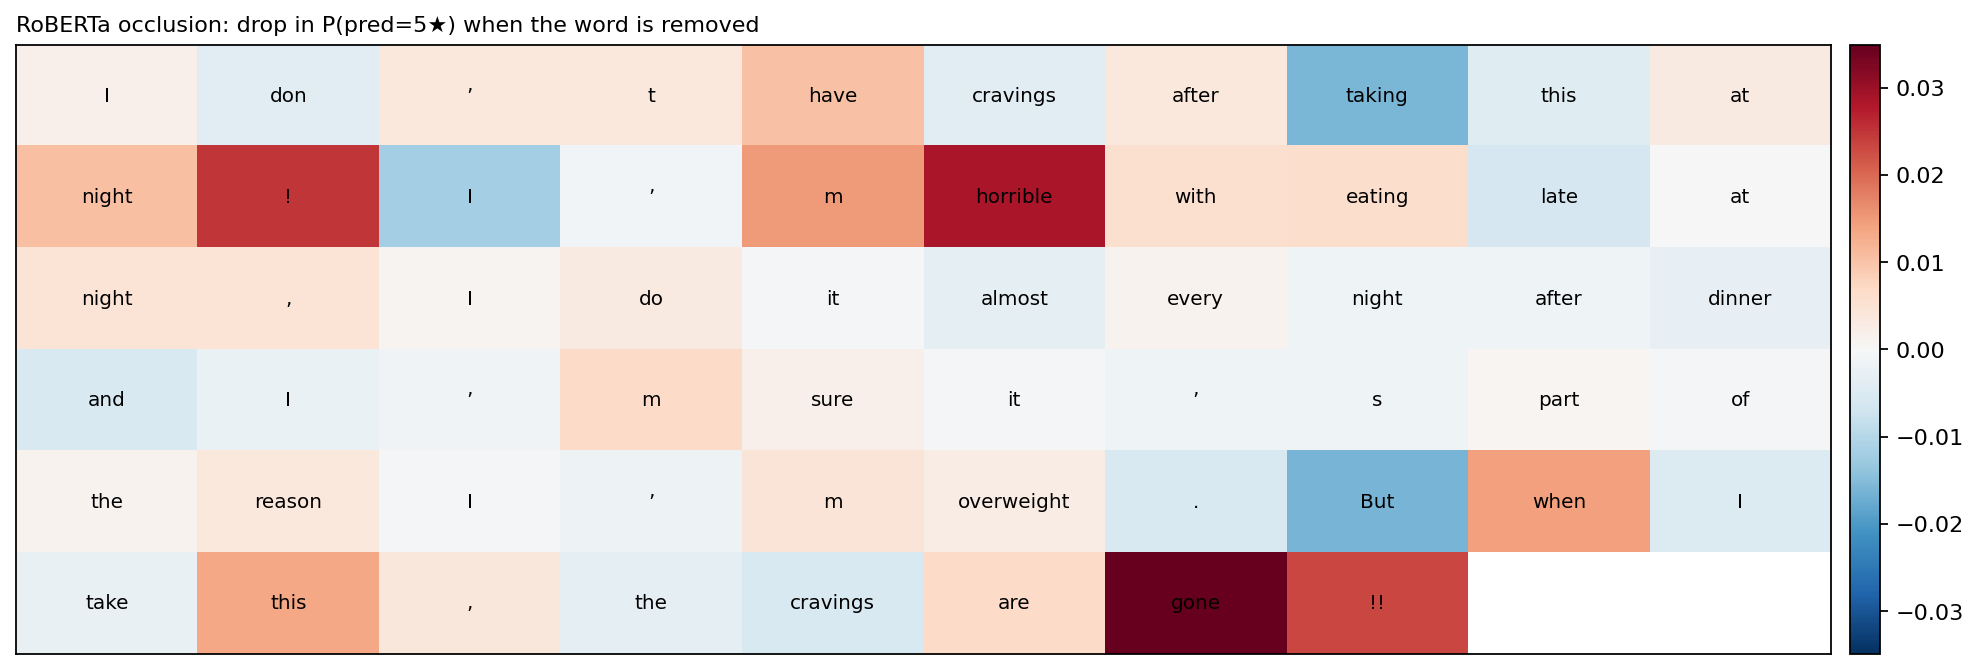

In [7]:
for p in sorted(Path("results/explain").glob("*.png")):
    print(p.name); display(Image(str(p)))

## For the report

`results/summary.md` has every table. The report (≤ 6 pages) should cover: architectures
and preprocessing (title recovery coverage, vocabulary size/coverage, truncation rates);
training setups; the main table (accuracy, macro-F1, MAE as mean ± std over 2 seeds); per-class
F1 and confusion matrices (middle classes, adjacent vs distant confusions); the ablation
(decided on validation); ≥5 + ≥2 qualitative examples with your hypotheses; the token-importance
figure; limitations (2 seeds, heuristic tags, attention ≠ explanation, body-only text for any
review whose title could not be recovered).